In [168]:
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [169]:
from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Literal
from search1api_langchain import Search1APIToolkit
from langchain.agents import create_agent
from datetime import date
from langchain.tools import tool
import requests

In [170]:
class FlowState(BaseModel):
    question: str = Field(description="The question to be answered")
    category: Literal['coding', 'google_search', 'weather'] = Field(description="The category of the question", default="google_search")
    answer: str = Field(description="The answer to the question", default="") 

In [171]:
class QuestionCategory(BaseModel):
    category: Literal['coding', 'google_search', 'weather'] = Field(description="The category of the question") 

In [172]:
llm = ChatOllama(model="qwen3:1.7b")

In [173]:
google_search_agent = create_agent(
    model=llm,
    tools=Search1APIToolkit().get_tools(),
    system_prompt=(
        f"Today's date is {date.today().isoformat()}. "
        "When answering questions about events, scores, or current status, "
        "always use the search tool rather than relying on your own knowledge, "
        "since your training data may be outdated. If search results don't "
        "clearly answer the question, say so rather than guessing."
    ),
)

In [174]:
@tool
def get_weather(city: str):
    """Provides the current weather for a given city."""
    geo = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                       params={"name": city, "count": 1}).json()["results"][0]
    w = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": geo["latitude"], "longitude": geo["longitude"],
                             "current": "temperature_2m,wind_speed_10m"}).json()["current"]
    return f"Weather in {city}: {w['temperature_2m']}°C, wind {w['wind_speed_10m']} km/h"

weather_agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are an agent and can provide weather details",
)

In [175]:
def check_question_category(state: FlowState) -> QuestionCategory:
    st_llm = llm.with_structured_output(QuestionCategory)
    res = st_llm.invoke("I want to know the category of the question: " + state.question)
    state.category = res.category
    return state

In [176]:
flow = FlowState(question="What is the weather of France?")
check_question_category(flow)

FlowState(question='What is the weather of France?', category='coding', answer='')

In [177]:
def route(state:FlowState) ->  Literal['coding', 'google_search', 'weather']:
    return state.category

In [178]:
def coding_node(state: FlowState) -> FlowState:
    print("Coding Node")
    res = llm.invoke("You are a coding expert and I want to know the answer to the coding question: " + state.question)
    state.answer = res.content
    return state

In [179]:
def google_search_node(state: FlowState) -> FlowState:
    print("Google Search Node")
    res = google_search_agent.invoke(
        {"messages": [{"role": "user", "content": state.question}]},
        config={"configurable": {"thread_id": "1"}},
    )
    state.answer = res["messages"][-1].content
    return state

In [180]:
def weather_node(state: FlowState) -> FlowState:
    print("Weather Node")
    res = weather_agent.invoke(
        {"messages": [{"role": "user", "content": state.question}]},
        config={"configurable": {"thread_id": "1"}},
    )
    state.answer = res["messages"][-1].content
    return state

In [181]:
graph = StateGraph(FlowState)

In [182]:
graph.add_node("check_question_category", check_question_category)
graph.add_node("coding", coding_node)
graph.add_node("google_search", google_search_node)
graph.add_node("weather", weather_node)

graph.add_edge(START, "check_question_category")
graph.add_conditional_edges("check_question_category", route)
graph.add_edge("coding", END)
graph.add_edge("google_search", END)
graph.add_edge("weather", END)

graph = graph.compile()

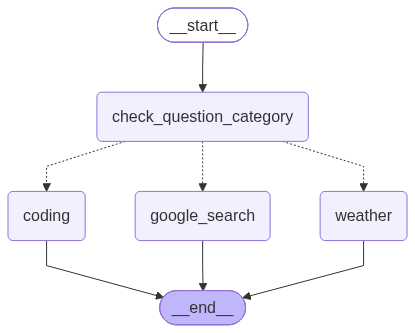

In [183]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [184]:
res = graph.invoke({"question": "what is weather in pune right now?"})

Weather Node


In [185]:
res


{'question': 'what is weather in pune right now?',
 'category': 'weather',
 'answer': 'The current weather in Pune is **33.3°C** with a wind speed of **9.2 km/h**. It’s a pleasant temperature for the day! 🌞'}